# 1.4 — Laboratorinio reikmens rūšis iš nuotraukos: konvoliucinis neuroninis tinklas (CNN)

**Pritaikyta iš kurso** [CNN užrašinio](https://colab.research.google.com/drive/1wx-OBEcjPhAfv8AZ5Fl59mp7RY5Hm0Ql?usp=sharing).

**Ką daro originalas.** CIFAR-10 nuotraukas (lėktuvas, automobilis, paukštis…) klasifikuoja CNN: `Conv2D` filtrai aptinka vietinius šablonus, `MaxPooling2D` mažina erdvinį dydį, tankūs sluoksniai pateikia klasės balus. Rodomi išmokti filtrai ir požymių žemėlapiai, mokymo kreivės, o antroje dalyje palyginimui mokomas paprastas daugiasluoksnis perceptronas (MLP).

**Kas pakeista.** Vietoj CIFAR-10 — trys kliento katalogo laboratorinių reikmenų klasės; vietoj 50 000 vaizdų — apie 120 mokymo nuotraukų. Dėl mažo rinkinio pridėta paprasta duomenų augmentacija (atsitiktinis apvertimas ir pasukimas), ankstyvasis stabdymas ir klaidų peržiūra. Architektūros idėja (Conv → Pool → Dense) ir MLP palyginimas išlaikyti.


## Duomenys ir jų ryšys su klientu

Kliento katalogo kainynuose yra **vizualiai atpažįstamų laboratorinių reikmenų** (plastikiniai PCR ir pipetavimo reikmenys). Naudojamos trys klasės:

| Klasė | Kas tai | Atitikmuo kataloge |
|---|---|---|
| `antgaliai` | pipečių antgaliai, antgalių dėžutės / stoveliai | filtruoti antgaliai stoveliuose |
| `mikro_megintuvelis` | PCR mėgintuvėliai, 8 mėgintuvėlių juostelės, 1,5 ml mikromėgintuvėliai | PCR mėgintuvėliai ir juostelės |
| `mikroplokstele` | 96 / 384 / 24 / 6 šulinėlių plokštelės | PCR plokštelės, mikroplokštelės |

**Kilmė.** Tai **viešos nuotraukos iš Wikimedia Commons ir Openverse (Flickr ir kt.)**, ne kliento ir ne studento darytos. Kiekviena nuotrauka rankiniu būdu peržiūrėta; atmesti piešiniai, įranga ir scenos, kur daiktas nepagrindinis. Licencijos (CC0, viešas naudojimas, CC BY, CC BY-SA, CC BY-NC / NC-SA) ir autoriai išsaugoti `metadata.csv`; CC BY / BY-SA reikalauja nurodyti autorių pristatyme.

**Padalijimas.** Visos vieno autoriaus nuotraukos patenka į tą pačią `train` / `val` / `test` aibę, kad tos pačios fotosesijos ar fono kadrai nebūtų ir mokyme, ir teste.

**Paskirtis ir ribos.** Tai **pagalbinė katalogo / sandėlio prekių grupavimo užduotis**, ne pirkimų dokumentų analizė. Iš nuotraukos negalima nustatyti tūrio, sterilumo, gamintojo ar SKU. Rinkinys mažas, todėl rezultatai turi didelę paklaidą.


## 1. Įkelti vaizdus

`image_dataset_from_directory` klasę nustato pagal aplanko pavadinimą. Nuotraukos apkerpamos iki kvadrato ir sumažinamos iki 128 × 128 pikselių.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = Path(os.getenv("TENDER_FIT_IMAGES_DIR", PROJECT / "private" / "1_4_vaizdai" / "galutinis"))
CLASS_NAMES = ["antgaliai", "mikro_megintuvelis", "mikroplokstele"]
assert DATA_ROOT.exists(), f"Nerastas {DATA_ROOT}"
for split in ("train", "val", "test"):
    counts = {c: len(list((DATA_ROOT / split / c).glob("*.jpg"))) for c in CLASS_NAMES}
    print(f"{split:5}", counts, "iš viso", sum(counts.values()))
print("TensorFlow", tf.__version__)

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16

def image_split(name, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        DATA_ROOT / name, labels="inferred", label_mode="int", class_names=CLASS_NAMES,
        image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED if shuffle else None,
        crop_to_aspect_ratio=True)

train_ds = image_split("train", True).prefetch(tf.data.AUTOTUNE)
val_ds = image_split("val", False).prefetch(tf.data.AUTOTUNE)
test_ds = image_split("test", False).prefetch(tf.data.AUTOTUNE)
y_test = np.concatenate([y.numpy() for _, y in test_ds])


train {'antgaliai': 41, 'mikro_megintuvelis': 34, 'mikroplokstele': 54} iš viso 129
val   {'antgaliai': 9, 'mikro_megintuvelis': 8, 'mikroplokstele': 12} iš viso 29
test  {'antgaliai': 13, 'mikro_megintuvelis': 10, 'mikroplokstele': 16} iš viso 39
TensorFlow 2.19.0
Found 129 files belonging to 3 classes.


Found 29 files belonging to 3 classes.


Found 39 files belonging to 3 classes.


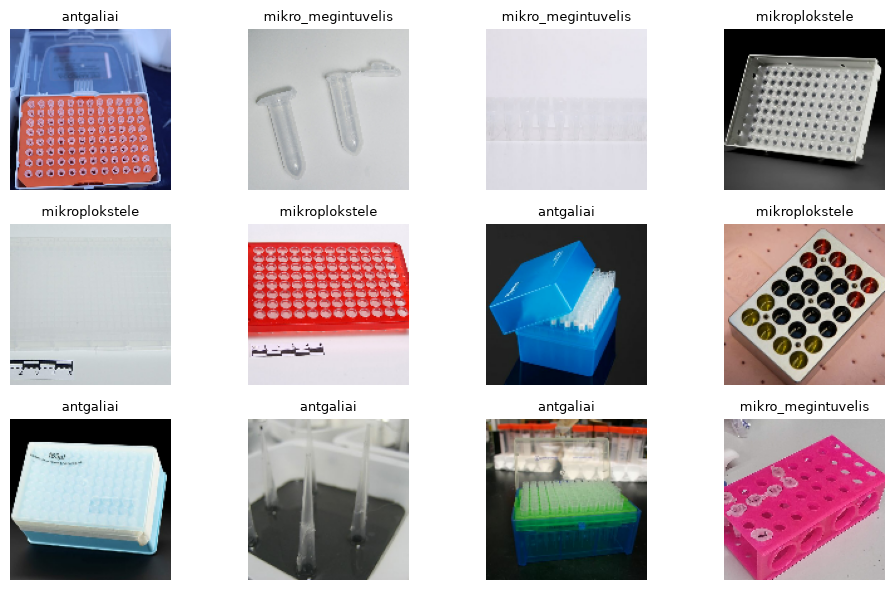

In [2]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(min(12, len(images))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8")); plt.title(CLASS_NAMES[int(labels[i])], fontsize=9); plt.axis("off")
plt.tight_layout(); plt.show()


## 2. CNN architektūra

- `Rescaling(1/255)` — pikseliai iš 0–255 į 0–1.
- Augmentacija (`RandomFlip`, `RandomRotation`, `RandomZoom`) veikia **tik mokymo metu** ir sukuria įvairesnių vaizdų variantų.
- Trys `Conv2D` + `MaxPooling2D` blokai mokosi vis sudėtingesnių šablonų (kraštai → apskritimai, šulinėlių tinklelis, kūgio forma).
- `GlobalAveragePooling2D` sumažina parametrų skaičių (mažam rinkiniui saugiau nei `Flatten`), `Dropout(0.4)` mažina persimokymą, paskutinis `Dense(3)` grąžina tris logitus.


In [3]:
from tensorflow.keras import layers

augment = tf.keras.Sequential([layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.15),
                               layers.RandomZoom(0.15)], name="augmentacija")
inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3))
x = augment(inputs)
x = layers.Rescaling(1.0 / 255)(x)
first_map = layers.Conv2D(16, 3, padding="same", activation="relu", name="pirmas_conv")(x)
x = layers.MaxPooling2D()(first_map)
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D()(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
logits = layers.Dense(len(CLASS_NAMES))(x)
cnn_model = tf.keras.Model(inputs, logits, name="reikmenu_cnn")
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
cnn_model.summary()


Model: "reikmenu_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentacija (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pirmas_conv (Conv2D)            │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Mokymas

Mokoma su `train`, geriausi svoriai renkami pagal `val` nuostolį. `test` nenaudojamas nei mokymui, nei modelio pasirinkimui.


<venv>/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epochų: 45 | geriausias val_accuracy: 0.621


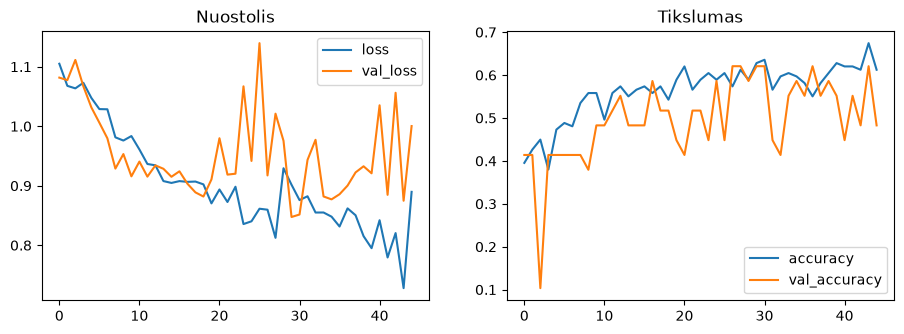

In [4]:
history = cnn_model.fit(train_ds, validation_data=val_ds, epochs=80, verbose=0,
                        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                                                    restore_best_weights=True)])
h = pd.DataFrame(history.history)
print("Epochų:", len(h), "| geriausias val_accuracy:", round(h.val_accuracy.max(), 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Nuostolis"); h[["accuracy", "val_accuracy"]].plot(ax=ax[1], title="Tikslumas")
plt.show()


## 4. Išmokti filtrai ir požymių žemėlapiai

Filtras — maža išmokta svorių matrica; požymių žemėlapis — jo atsakas visame vaizde. Tai padeda suprasti mechanizmą, bet neįrodo, kokią prasmę neuronas „atpažįsta“.


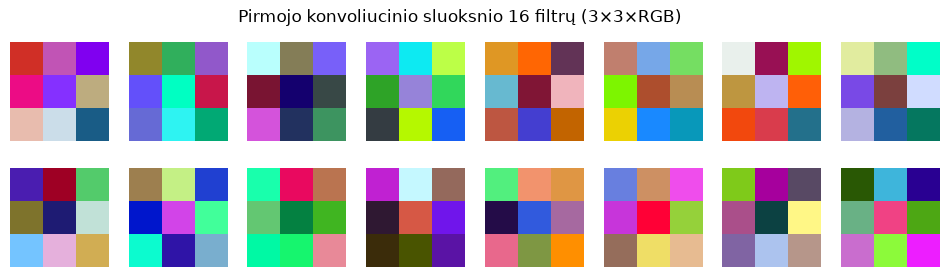

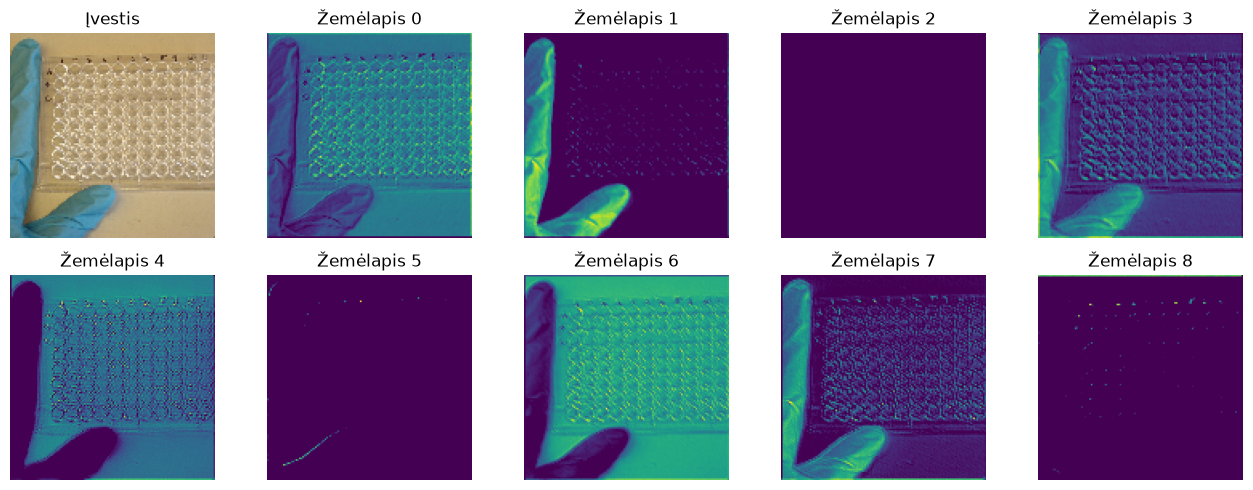

In [5]:
filters, _ = cnn_model.get_layer("pirmas_conv").get_weights()
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i, ax in enumerate(axes.flat):
    f = filters[:, :, :, i]; ax.imshow((f - f.min()) / (np.ptp(f) + 1e-8)); ax.axis("off")
plt.suptitle("Pirmojo konvoliucinio sluoksnio 16 filtrų (3×3×RGB)"); plt.show()

feature_model = tf.keras.Model(cnn_model.input, first_map)
test_images = np.concatenate([x.numpy() for x, _ in test_ds])
example = test_images[np.where(y_test == CLASS_NAMES.index("mikroplokstele"))[0][0]][None]
maps = feature_model(example, training=False).numpy()[0]
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
axes.flat[0].imshow(example[0].astype("uint8")); axes.flat[0].set_title("Įvestis"); axes.flat[0].axis("off")
for i, ax in enumerate(list(axes.flat)[1:]):
    ax.imshow(maps[:, :, i], cmap="viridis"); ax.set_title(f"Žemėlapis {i}"); ax.axis("off")
plt.tight_layout(); plt.show()


## 5. Palyginimas su daugiasluoksniu perceptronu (MLP)

MLP iš karto „išlygina“ sumažintą vaizdą į vektorių ir neturi konvoliucijų lokalumo. Tai mokomasis palyginimas, ne įrodymas, kad bet kuris CNN visada geresnis.


In [6]:
mlp_model = tf.keras.Sequential([
    tf.keras.Input(shape=(*IMAGE_SIZE, 3)), augment, layers.Rescaling(1.0 / 255), layers.Resizing(32, 32),
    layers.Flatten(), layers.Dense(64, activation="relu"), layers.Dropout(0.3), layers.Dense(len(CLASS_NAMES)),
], name="reikmenu_mlp")
mlp_model.compile(optimizer="adam", loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])
mlp_model.fit(train_ds, validation_data=val_ds, epochs=80, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])
print("MLP parametrų:", mlp_model.count_params(), "| CNN parametrų:", cnn_model.count_params())


MLP parametrų: 196867 | CNN parametrų: 23779


## 6. Galutinis įvertinimas testo aibėje

Testo aibė maža, todėl viena klaida keičia tikslumą keliais procentiniais punktais. Svarbu žiūrėti painiavos matricą ir klaidingų prognozių pavyzdžius.


== CNN: testo tikslumas 0.359 (14/39)
                    precision    recall  f1-score   support

         antgaliai       0.36      0.31      0.33        13
mikro_megintuvelis       0.35      0.70      0.47        10
    mikroplokstele       0.38      0.19      0.25        16

          accuracy                           0.36        39
         macro avg       0.36      0.40      0.35        39
      weighted avg       0.36      0.36      0.33        39

Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):
                     antgaliai  mikro_megintuvelis  mikroplokstele
antgaliai                   4                   4               5
mikro_megintuvelis          3                   7               0
mikroplokstele              4                   9               3
== MLP: testo tikslumas 0.256 (10/39)
                    precision    recall  f1-score   support

         antgaliai       0.38      0.23      0.29        13
mikro_megintuvelis       0.28      0.70      0.40      

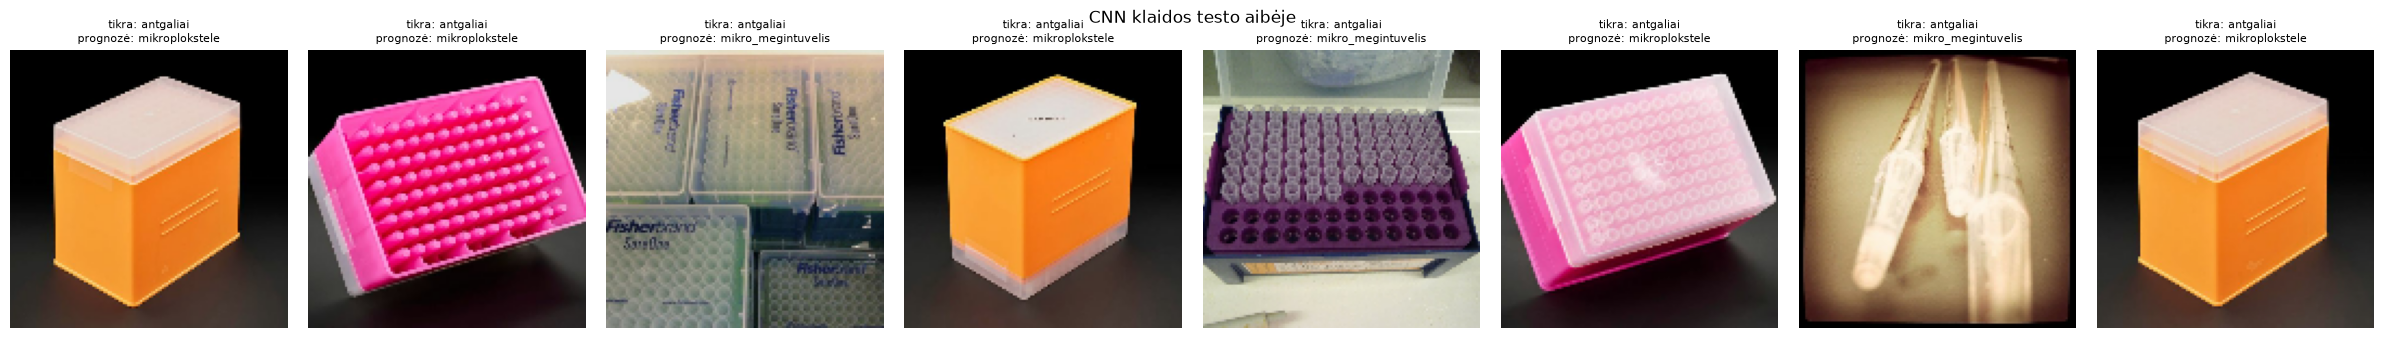

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def evaluate(model, name):
    probs = model.predict(test_ds, verbose=0)
    pred = probs.argmax(axis=1)
    print(f"== {name}: testo tikslumas {accuracy_score(y_test, pred):.3f} ({(pred == y_test).sum()}/{len(y_test)})")
    print(classification_report(y_test, pred, target_names=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(y_test, pred)
    print("Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):\n", pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))
    return pred

def show_mistakes(pred, title, limit=8):
    images = np.concatenate([x.numpy() for x, _ in test_ds])
    wrong = np.where(pred != y_test)[0][:limit]
    if len(wrong) == 0:
        print("Klaidų nėra."); return
    plt.figure(figsize=(3 * len(wrong), 3.4))
    for k, i in enumerate(wrong):
        plt.subplot(1, len(wrong), k + 1)
        plt.imshow(images[i].astype("uint8")); plt.axis("off")
        plt.title(f"tikra: {CLASS_NAMES[y_test[i]]}\nprognozė: {CLASS_NAMES[pred[i]]}", fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

cnn_pred = evaluate(cnn_model, "CNN")
mlp_pred = evaluate(mlp_model, "MLP")
show_mistakes(cnn_pred, "CNN klaidos testo aibėje")
results_dir = PROJECT / "private" / "rezultatai"; results_dir.mkdir(exist_ok=True)
pd.DataFrame({"y": y_test, "cnn": cnn_pred, "mlp": mlp_pred}).to_csv(results_dir / "1_4_cnn_test.csv", index=False)
model_dir = PROJECT / "private" / "modeliai"; model_dir.mkdir(exist_ok=True)
cnn_model.save(model_dir / "1_4_reikmenu_cnn.keras")


## 7. Išvados

Interpretacija — pristatymo gide (`docs/1_3_1_5_pristatymo_gidas.md`). Tas pats rinkinys ir padalijimas naudojami 1.5 perkeltinio mokymo užrašinyje.
